In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [4]:
df = pd.read_excel('/content/Online Retail.xlsx')

print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [6]:
df.rename(columns={
    'CustomerID': 'Customer ID',
    'InvoiceNo': 'Invoice',
    'UnitPrice': 'Price'
}, inplace=True)

df = df.dropna(subset=['Customer ID'])
df = df[df['Quantity'] > 0]
df = df[df['Price'] > 0]

print(df.shape)

(397884, 8)


In [7]:
#rfm analysis
df['Amount'] = df['Quantity'] * df['Price']

today = df['InvoiceDate'].max()

rfm = df.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (today - x.max()).days,
    'Invoice': 'nunique',
    'Amount': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

print(rfm.head())

             Recency  Frequency  Monetary
Customer ID                              
12346.0          325          1  77183.60
12347.0            1          7   4310.00
12348.0           74          4   1797.24
12349.0           18          1   1757.55
12350.0          309          1    334.40


In [8]:
#scaling
scaler = StandardScaler()
X = scaler.fit_transform(rfm)

In [9]:
#k-means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

rfm['KMeans'] = kmeans.fit_predict(X)

print(rfm.head())

             Recency  Frequency  Monetary  KMeans
Customer ID                                      
12346.0          325          1  77183.60       0
12347.0            1          7   4310.00       1
12348.0           74          4   1797.24       1
12349.0           18          1   1757.55       1
12350.0          309          1    334.40       0


In [10]:
#dbscan
db = DBSCAN(eps=0.5, min_samples=5)

rfm['DBSCAN'] = db.fit_predict(X)

print(rfm.head())

             Recency  Frequency  Monetary  KMeans  DBSCAN
Customer ID                                              
12346.0          325          1  77183.60       0      -1
12347.0            1          7   4310.00       1       0
12348.0           74          4   1797.24       1       0
12349.0           18          1   1757.55       1       0
12350.0          309          1    334.40       0       0


In [11]:
#pca
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

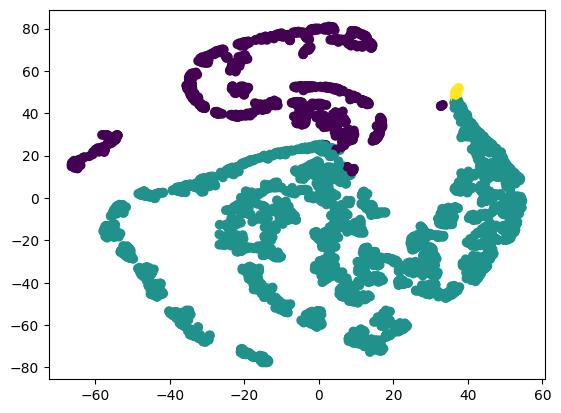

In [12]:
#tsne
tsne = TSNE(n_components=2, random_state=42)

X_tsne = tsne.fit_transform(X_pca)

plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=rfm['KMeans'])
plt.show()

In [13]:
#marketing personas
print(rfm.groupby('KMeans')[['Recency', 'Frequency', 'Monetary']].mean())

           Recency  Frequency      Monetary
KMeans                                     
0       246.106285   1.582255    631.424206
1        40.454180   4.672755   1855.942345
2         5.038462  66.423077  85904.351538
